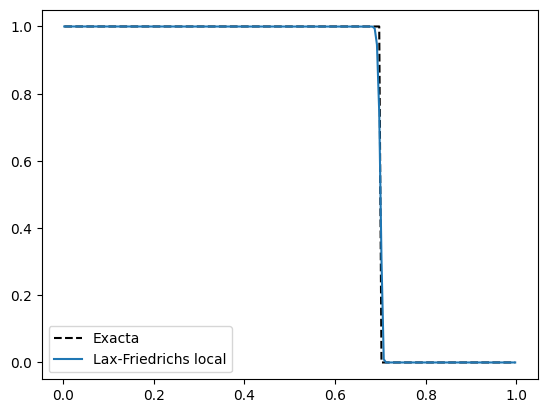

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def f(u):
    return 0.5 * u**2                     # el flujo de Burgers

def flujo_lf(ul, ur):
    # ul = valor de la casilla izquierda de la cara, ur = valor de la derecha
    a = np.maximum(np.abs(ul), np.abs(ur))        # velocidad máxima de la onda en esa cara
    return 0.5 * (f(ul) + f(ur)) - 0.5 * a * (ur - ul)

def simular(flujo, u0, N=200, t_final=0.8, cfl=0.8, L=1.0):
    dx = L / N
    x = (np.arange(N) + 0.5) * dx
    u = u0(x)
    t = 0.0
    while t < t_final:
        dt = min(cfl * dx / np.max(np.abs(u)), t_final - t)
        up = np.pad(u, 1, mode="edge")            # bordes abiertos: copia el valor de la orilla
        F = flujo(up[:-1], up[1:])                # flujo en cada cara (N+1 caras)
        u = u - dt / dx * (F[1:] - F[:-1])        # entra por la izquierda, sale por la derecha
        t += dt
    return x, u

def u0_choque(x):
    return np.where(x < 0.3, 1.0, 0.0)

def exacta_choque(x, t, x0=0.3):
    return np.where(x < x0 + 0.5 * t, 1.0, 0.0)

x, u = simular(flujo_lf, u0_choque)
plt.plot(x, exacta_choque(x, 0.8), "k--", label="Exacta")
plt.plot(x, u, label="Lax-Friedrichs local")
plt.legend(); plt.show()

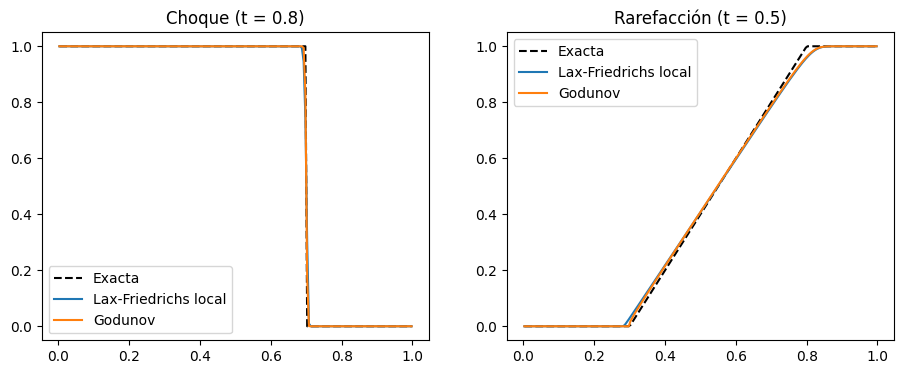

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def f(u):
    return 0.5 * u**2                     # el flujo de Burgers

def flujo_lf(ul, ur):
    # ul = valor de la casilla izquierda de la cara, ur = valor de la derecha
    a = np.maximum(np.abs(ul), np.abs(ur))        # velocidad máxima de la onda en esa cara
    return 0.5 * (f(ul) + f(ur)) - 0.5 * a * (ur - ul)

def simular(flujo, u0, N=200, t_final=0.8, cfl=0.8, L=1.0):
    dx = L / N
    x = (np.arange(N) + 0.5) * dx
    u = u0(x)
    t = 0.0
    while t < t_final:
        dt = min(cfl * dx / np.max(np.abs(u)), t_final - t)
        up = np.pad(u, 1, mode="edge")            # bordes abiertos: copia el valor de la orilla
        F = flujo(up[:-1], up[1:])                # flujo en cada cara (N+1 caras)
        u = u - dt / dx * (F[1:] - F[:-1])        # entra por la izquierda, sale por la derecha
        t += dt
    return x, u

def u0_choque(x):
    return np.where(x < 0.3, 1.0, 0.0)

def exacta_choque(x, t, x0=0.3):
    return np.where(x < x0 + 0.5 * t, 1.0, 0.0)

def flujo_godunov(ul, ur):
    fl, fr = f(ul), f(ur)
    # Si ul <= ur (rarefacción): 0 si el abanico cruza la cara, si no, el flujo del lado correcto
    rar = np.where(ul >= 0, fl, np.where(ur <= 0, fr, 0.0))
    # Si ul > ur (choque): se elige el mayor de los dos flujos
    cho = np.maximum(fl, fr)
    return np.where(ul <= ur, rar, cho)

def u0_rarefaccion(x):
    return np.where(x < 0.3, 0.0, 1.0)

def exacta_rarefaccion(x, t, x0=0.3):
    return np.clip((x - x0) / t, 0.0, 1.0)     # abanico lineal entre x0 y x0 + t

casos = {
    "Choque (t = 0.8)": (u0_choque, exacta_choque, 0.8),
    "Rarefacción (t = 0.5)": (u0_rarefaccion, exacta_rarefaccion, 0.5),
}
metodos = {"Lax-Friedrichs local": flujo_lf, "Godunov": flujo_godunov}

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))      # dos gráficas lado a lado
for eje, (titulo, (u0, exacta, t_fin)) in zip(ejes, casos.items()):
    x = (np.arange(200) + 0.5) / 200
    eje.plot(x, exacta(x, t_fin), "k--", label="Exacta")
    for nombre, flujo in metodos.items():
        x, u = simular(flujo, u0, N=200, t_final=t_fin)
        eje.plot(x, u, label=nombre)
    eje.set_title(titulo)
    eje.legend()
plt.show()

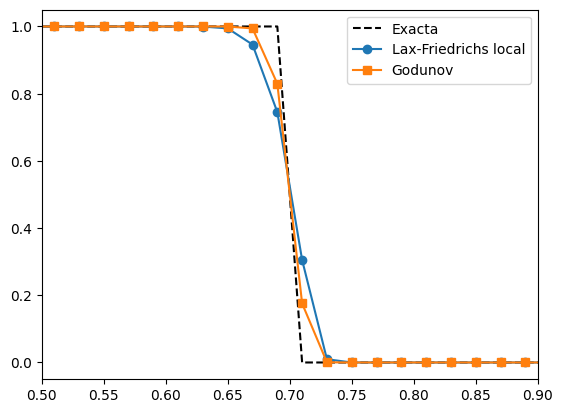

In [3]:
x, u_lf = simular(flujo_lf, u0_choque, N=50, t_final=0.8)
x, u_go = simular(flujo_godunov, u0_choque, N=50, t_final=0.8)

plt.plot(x, exacta_choque(x, 0.8), "k--", label="Exacta")
plt.plot(x, u_lf, "o-", label="Lax-Friedrichs local")
plt.plot(x, u_go, "s-", label="Godunov")
plt.xlim(0.5, 0.9)
plt.legend()
plt.show()

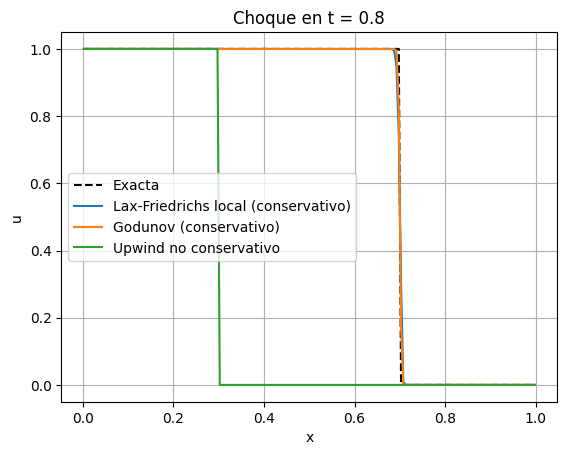

In [4]:
def f(u):
    return 0.5 * u**2                     # el flujo de Burgers

def flujo_lf(ul, ur):
    # ul = valor de la casilla izquierda de la cara, ur = valor de la derecha
    a = np.maximum(np.abs(ul), np.abs(ur))        # velocidad máxima de la onda en esa cara
    return 0.5 * (f(ul) + f(ur)) - 0.5 * a * (ur - ul)

def simular(flujo, u0, N=200, t_final=0.8, cfl=0.8, L=1.0):
    dx = L / N
    x = (np.arange(N) + 0.5) * dx
    u = u0(x)
    t = 0.0
    while t < t_final:
        dt = min(cfl * dx / np.max(np.abs(u)), t_final - t)
        up = np.pad(u, 1, mode="edge")            # bordes abiertos: copia el valor de la orilla
        F = flujo(up[:-1], up[1:])                # flujo en cada cara (N+1 caras)
        u = u - dt / dx * (F[1:] - F[:-1])        # entra por la izquierda, sale por la derecha
        t += dt
    return x, u

def u0_choque(x):
    return np.where(x < 0.3, 1.0, 0.0)

def exacta_choque(x, t, x0=0.3):
    return np.where(x < x0 + 0.5 * t, 1.0, 0.0)

def flujo_godunov(ul, ur):
    fl, fr = f(ul), f(ur)
    # Si ul <= ur (rarefacción): 0 si el abanico cruza la cara, si no, el flujo del lado correcto
    rar = np.where(ul >= 0, fl, np.where(ur <= 0, fr, 0.0))
    # Si ul > ur (choque): se elige el mayor de los dos flujos
    cho = np.maximum(fl, fr)
    return np.where(ul <= ur, rar, cho)

def u0_rarefaccion(x):
    return np.where(x < 0.3, 0.0, 1.0)

def exacta_rarefaccion(x, t, x0=0.3):
    return np.clip((x - x0) / t, 0.0, 1.0)     # abanico lineal entre x0 y x0 + t

def simular_no_conservativo(u0, N=200, t_final=0.8, cfl=0.8, L=1.0):
    dx = L / N
    x = (np.arange(N) + 0.5) * dx
    u = u0(x)
    t = 0.0
    while t < t_final:
        dt = min(cfl * dx / np.max(np.abs(u)), t_final - t)
        up = np.pad(u, 1, mode="edge")
        u = u - dt / dx * u * (up[1:-1] - up[:-2])    # u·uₓ escrito sin flujos
        t += dt
    return x, u

x, u_lf = simular(flujo_lf, u0_choque)
x, u_go = simular(flujo_godunov, u0_choque)
x, u_nc = simular_no_conservativo(u0_choque)

plt.plot(x, exacta_choque(x, 0.8), "k--", label="Exacta")
plt.plot(x, u_lf, label="Lax-Friedrichs local (conservativo)")
plt.plot(x, u_go, label="Godunov (conservativo)")
plt.plot(x, u_nc, label="Upwind no conservativo")
plt.title("Choque en t = 0.8")
plt.xlabel("x"); plt.ylabel("u")
plt.legend(); plt.grid(True)
plt.show()

Lax-Friedrichs local: orden observado = 1.00
Godunov: orden observado = 1.00


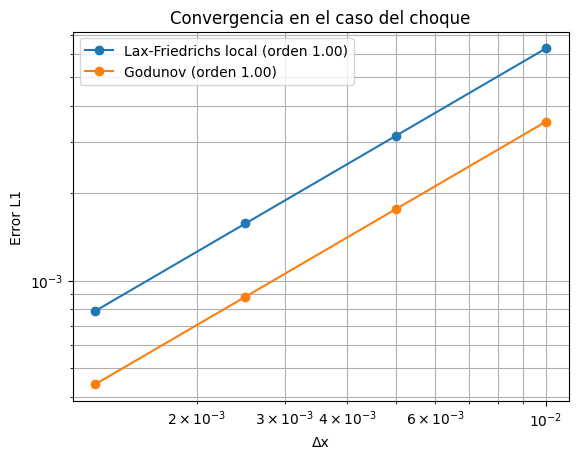

In [5]:
Ns = [100, 200, 400, 800]
dxs = [1 / n for n in Ns]

for nombre, flujo in {"Lax-Friedrichs local": flujo_lf, "Godunov": flujo_godunov}.items():
    errores = []
    for n in Ns:
        x, u = simular(flujo, u0_choque, N=n)
        errores.append(np.sum(np.abs(u - exacta_choque(x, 0.8))) / n)   # error L1
    pendiente = np.polyfit(np.log(dxs), np.log(errores), 1)[0]
    print(f"{nombre}: orden observado = {pendiente:.2f}")
    plt.loglog(dxs, errores, "o-", label=f"{nombre} (orden {pendiente:.2f})")

plt.xlabel("Δx"); plt.ylabel("Error L1")
plt.title("Convergencia en el caso del choque")
plt.legend(); plt.grid(True, which="both")
plt.show()